In [1]:
import pandas as pd
#load dataset
df = pd.read_csv(r"C:\Users\Admin\Downloads\data.csv")
#dataset first look
print("Car's dataset")
print(df)
#dataset info
print("Data set info")
print(df.info())


Car's dataset
          Make       Model  Year                Engine Fuel Type  Engine HP  \
0          BMW  1 Series M  2011     premium unleaded (required)      335.0   
1          BMW    1 Series  2011     premium unleaded (required)      300.0   
2          BMW    1 Series  2011     premium unleaded (required)      300.0   
3          BMW    1 Series  2011     premium unleaded (required)      230.0   
4          BMW    1 Series  2011     premium unleaded (required)      230.0   
...        ...         ...   ...                             ...        ...   
11909    Acura         ZDX  2012     premium unleaded (required)      300.0   
11910    Acura         ZDX  2012     premium unleaded (required)      300.0   
11911    Acura         ZDX  2012     premium unleaded (required)      300.0   
11912    Acura         ZDX  2013  premium unleaded (recommended)      300.0   
11913  Lincoln      Zephyr  2006                regular unleaded      221.0   

       Engine Cylinders Transmission 

In [2]:

# Check shape
print(df.shape)

# Check null values
print(df.isnull().sum())

#Drop null values
df = df.dropna()

# Drop duplicates
df = df.drop_duplicates()
print(df)

# Fill missing values
df['Engine HP'] = df['Engine HP'].fillna(df['Engine HP'].mean())
df['Engine Cylinders'] = df['Engine Cylinders'].fillna(df['Engine Cylinders'].median())
df['Number of Doors'] = df['Number of Doors'].fillna(df['Number of Doors'].mode()[0])

(11914, 16)
Make                    0
Model                   0
Year                    0
Engine Fuel Type        3
Engine HP              69
Engine Cylinders       30
Transmission Type       0
Driven_Wheels           0
Number of Doors         6
Market Category      3742
Vehicle Size            0
Vehicle Style           0
highway MPG             0
city mpg                0
Popularity              0
MSRP                    0
dtype: int64
          Make       Model  Year                Engine Fuel Type  Engine HP  \
0          BMW  1 Series M  2011     premium unleaded (required)      335.0   
1          BMW    1 Series  2011     premium unleaded (required)      300.0   
2          BMW    1 Series  2011     premium unleaded (required)      300.0   
3          BMW    1 Series  2011     premium unleaded (required)      230.0   
4          BMW    1 Series  2011     premium unleaded (required)      230.0   
...        ...         ...   ...                             ...        ...   
11909 

In [3]:
#description
print("summary analysis")
print(df.describe())

summary analysis
             Year    Engine HP  Engine Cylinders  Number of Doors  \
count  7735.00000  7735.000000       7735.000000      7735.000000   
mean   2012.14958   277.632062          5.825469         3.421332   
std       6.23167   115.529955          1.895593         0.895054   
min    1990.00000    55.000000          0.000000         2.000000   
25%    2010.00000   194.000000          4.000000         2.000000   
50%    2015.00000   270.000000          6.000000         4.000000   
75%    2016.00000   325.000000          6.000000         4.000000   
max    2017.00000  1001.000000         16.000000         4.000000   

       highway MPG     city mpg   Popularity          MSRP  
count   7735.00000  7735.000000  7735.000000  7.735000e+03  
mean      26.52980    19.468649  1513.098772  5.102826e+04  
std        7.78492     7.231534  1429.197317  7.153777e+04  
min       12.00000     7.000000     2.000000  2.000000e+03  
25%       22.00000    16.000000   520.000000  2.622500e+

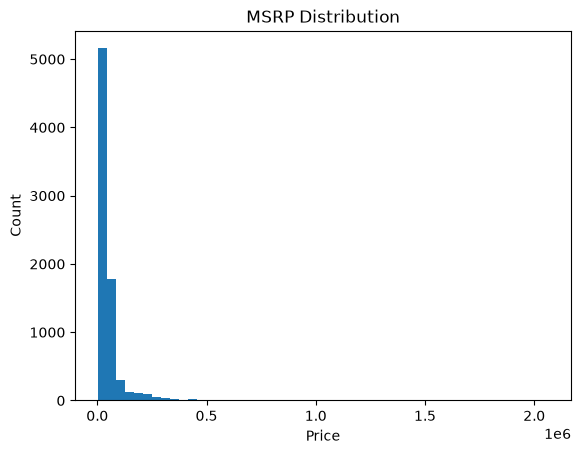

In [4]:
import matplotlib.pyplot as plt

# MSRP distribution
plt.hist(df['MSRP'], bins=50)
plt.title("MSRP Distribution")
plt.xlabel("Price")
plt.ylabel("Count")
plt.show()

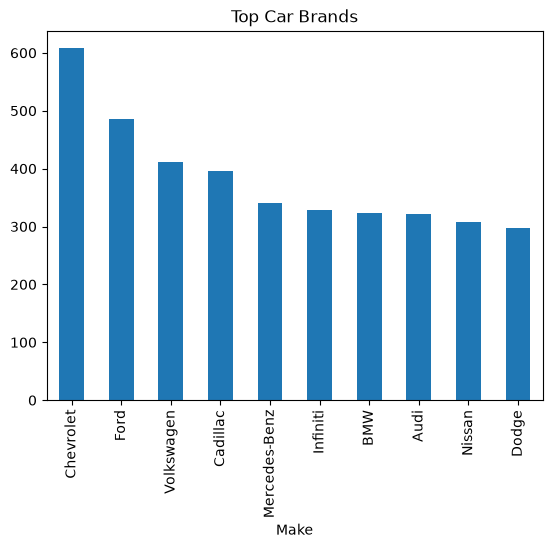

In [ ]:
top_brands = df['Make'].value_counts().head(10)
top_brands.plot(kind='bar')
plt.title("Top Car Brands")
plt.show()

In [6]:
corr = df[['MSRP','Engine HP','highway MPG','city mpg']].corr()
print(corr)

                 MSRP  Engine HP  highway MPG  city mpg
MSRP         1.000000   0.655522    -0.255595 -0.266632
Engine HP    0.655522   1.000000    -0.468328 -0.510151
highway MPG -0.255595  -0.468328     1.000000  0.818331
city mpg    -0.266632  -0.510151     0.818331  1.000000


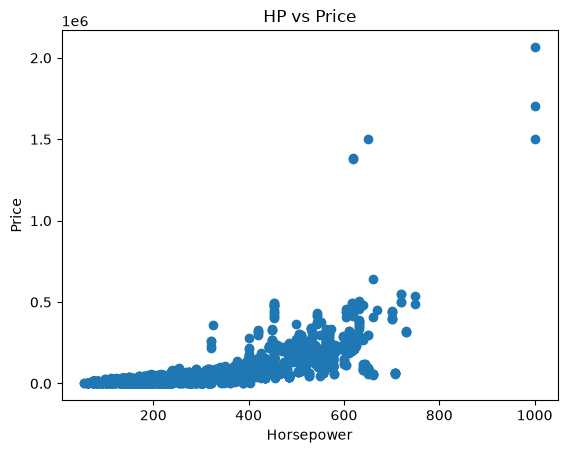

In [7]:
plt.scatter(df['Engine HP'], df['MSRP'])
plt.xlabel("Horsepower")
plt.ylabel("Price")
plt.title("HP vs Price")
plt.show()

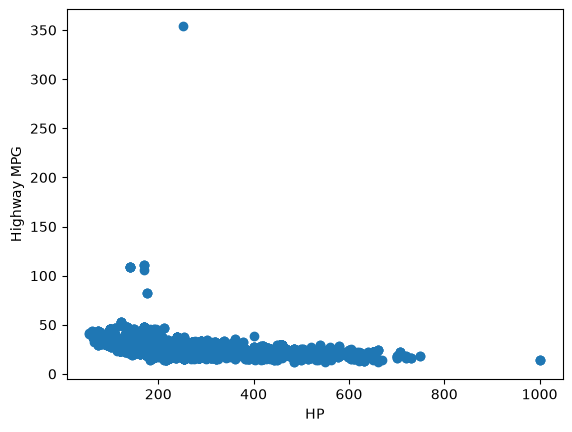

In [8]:
plt.scatter(df['Engine HP'], df['highway MPG'])
plt.xlabel("HP")
plt.ylabel("Highway MPG")
plt.show()

In [9]:
df.groupby('Make')['MSRP'].mean().sort_values(ascending=False).head(10)

Make
Bugatti         1.757224e+06
Maybach         5.462219e+05
Rolls-Royce     3.511306e+05
Lamborghini     3.315673e+05
Bentley         2.471693e+05
McLaren         2.398050e+05
Ferrari         2.373838e+05
Spyker          2.149900e+05
Aston Martin    1.981235e+05
Maserati        1.136845e+05
Name: MSRP, dtype: float64